In [1]:
# This code:
#     - produces plots showing the relationship between dry-bulb temperature (T) and simplified wet-bulb globe temperature (sWBGT)
#     - produces the equations for the upper and lower bounds of the T-sWBGT relationship


In [2]:
# Import modules
import numpy as np
import sys, os
import matplotlib.pyplot as plt

EU = os.path.expanduser

# Specify directory for atmos Python package. atmos can be downloaded from: https://github.com/AusClimateService/atmos
sys.path.append(EU("/home/565/cdr565/heat/others_code/atmos/"))
from atmos import moisture


In [3]:
# Set output directory
dir_out = './heat/figures/'


In [4]:
# Create 3-dimensional arrays for gridded calculations

t_array = np.arange(-20,50.5,0.5)
rh_array = np.arange(0,100.5,0.5)

t_3d = np.zeros([len(rh_array),len(t_array)]) * np.nan
for i in np.arange(len(rh_array)):
    t_3d[i,:] = t_array

rh_3d = np.zeros([len(rh_array),len(t_array)]) * np.nan
for i in np.arange(len(t_array)):
    rh_3d[:,i] = rh_array


In [5]:
# Calculate vapour pressure, sWBGT, and the difference between sWBGT and T

vap_pres = moisture.vapour_pressure_from_relative_humidity(t_3d+273.15, rh_3d/100)
swbgt = 0.567 * t_3d + 0.393 * (vap_pres/100) + 3.94
swbgt_t_diff = swbgt - t_3d


Max and min difference between WBGT and T
30.9
-17.7


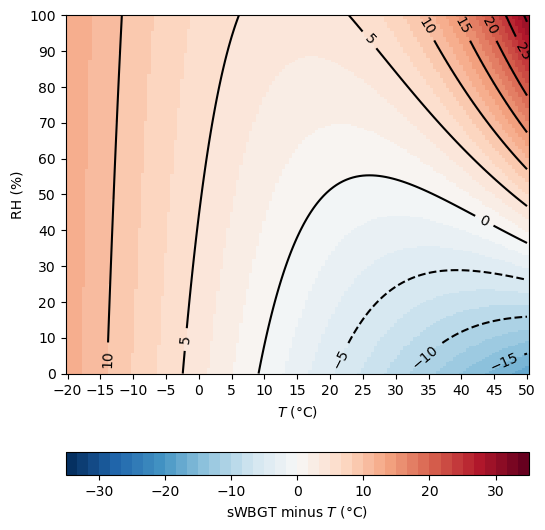

In [6]:
# Plot differences between T and WBGT for T (x-axis) and RH (y-axis)

set_round = 1

print('Max and min difference between WBGT and T')
print(np.round(np.nanmax(swbgt_t_diff),set_round))
print(np.round(np.nanmin(swbgt_t_diff),set_round))


x_min = -20.5
x_max = 50.5
y_min = -2
y_max = 37


plot_width = 5.56
plot_height = 5.52

fig = plt.figure(figsize=(plot_width, plot_height))

set_cmap = 'RdBu_r'
set_cmap = plt.get_cmap(set_cmap, 42) # Make colourbar discrete

plt.pcolor(t_array, rh_array, swbgt_t_diff, cmap=set_cmap,
          vmin=-35, vmax=35)

plt.colorbar(orientation='horizontal', label='sWBGT minus $\it{T}$ (\N{degree sign}C)')

plt.xlabel('$\it{T}$ (\N{degree sign}C)')
plt.ylabel('RH (%)')


plt.xticks(np.arange(-20, 51, 5.0))
plt.yticks(np.arange(0, 101, 10.0))


set_levels = np.arange(-30,31,5)

ax = plt.contour(t_array, rh_array, swbgt_t_diff, levels=set_levels, colors='k')
plt.clabel(ax, ax.levels, fontsize=10, colors='k')

plt.tight_layout()

# Save file
fname_out = dir_out + 'T_vs_RH_vs_sWBGTminusT'
plt.savefig(fname_out + '.png', bbox_inches='tight', pad_inches=0.2, dpi=600)


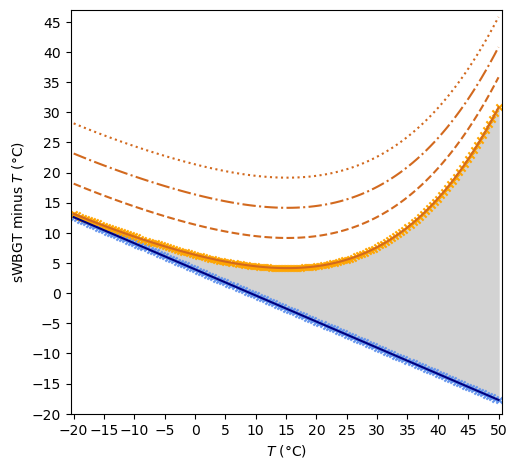

In [7]:
# Plot T (x-axis) vs sWBGT minus T (y-axis)

min_threshold_2 = np.nanmin(swbgt_t_diff,0)
max_threshold_2 = np.nanmax(swbgt_t_diff,0)

x_min = -20.5
x_max = 50.5
y_min = -20
y_max = 47

plot_width = 5.56 # 14 /2
plot_height = plot_width * (y_max - y_min) / (x_max - x_min)
fig = plt.figure(figsize=(plot_width, plot_height))

set_msize = 20
set_marker = 'x'

# Polyfit min threshold
z1_t = np.polyfit(t_array,min_threshold_2,1)
p1_t = np.poly1d(z1_t)
xp1_t = np.linspace(np.nanmin(t_array), np.nanmax(t_array), 100)


# Polyfit max threshold
z4_t = np.polyfit(t_array,max_threshold_2,4)
p4_t = np.poly1d(z4_t)
xp4_t = np.linspace(np.nanmin(t_array), np.nanmax(t_array), 100)


plt.fill_between(xp1_t,p1_t(xp1_t),p4_t(xp1_t),color='lightgrey')


plt.scatter(t_array,min_threshold_2,s=set_msize,marker=set_marker,c='cornflowerblue')
plt.plot(xp1_t, p1_t(xp1_t),c='navy')

plt.scatter(t_array,max_threshold_2,s=set_msize,marker=set_marker,c='orange')
plt.plot(xp4_t, p4_t(xp4_t),c='chocolate')



# Curve plus buffers
plt.plot(xp4_t, p4_t(xp4_t)+5,c='chocolate',linestyle='--')
plt.plot(xp4_t, p4_t(xp4_t)+10,c='chocolate',linestyle='-.')
plt.plot(xp4_t, p4_t(xp4_t)+15,c='chocolate',linestyle=':')



plt.xlabel('$\it{T}$ (\N{degree sign}C)')
plt.ylabel('sWBGT minus $\it{T}$ (\N{degree sign}C)')


plt.xlim([x_min,x_max])
plt.ylim([y_min,y_max])

plt.xticks(np.arange(-20, 51, 5.0))
plt.yticks(np.arange(y_min, 50, 5.0))

# Save file
fname_out = dir_out + 'T_vs_sWBGTminusT'
plt.savefig(fname_out + '.png', bbox_inches='tight', pad_inches=0.2, dpi=600)


In [8]:
# print('Minimum contour')
# print('z1_t = ' + str(z1_t))
# print('p1_t = ' + str(p1_t))
# print()

# print('Maximum contour')
# print('z4_t = ' + str(z4_t))
# print('p4_t = ' + str(p4_t))


In [9]:
# Print equation defining minmum contour
print('Minimum contour = ')
if len(z1_t) == 2:
    print(str(z1_t[0]) + ' * T' + ' + ' + 
          str(z1_t[1]))
else:
    print('Error: script only works if len(z1_t) == 2')
    sys.exit()

print('')

# Print equation defining maximum contour
print('Maximum contour = ')
if len(z4_t) == 5:
    print(str(z4_t[0]) + ' * T^4' + ' + ' + 
          str(z4_t[1]) + ' * T^3' + ' + ' + 
          str(z4_t[2]) + ' * T^2' + ' + ' + 
          str(z4_t[3]) + ' * T' + ' + ' + 
          str(z4_t[4]))
else:
    print('Error: script only works if len(z4_t) == 5')
    sys.exit()


Minimum contour = 
-0.43299999999999994 * T + 3.94

Maximum contour = 
1.9156979499884064e-06 * T^4 + 9.480906666175674e-05 * T^3 + 0.005352739223489789 * T^2 + -0.25536263707481316 * T + 6.357423666662269
